<a href="https://colab.research.google.com/github/Hafsahshaikh/Generative-AI-Projects/blob/main/Autoencoder.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
pip install tensorflow

In [2]:
import tensorflow as tf
from tensorflow.keras import layers, models
import numpy as np
import matplotlib.pyplot as plt

In [3]:
(x_train, _), (x_test, _) = tf.keras.datasets.mnist.load_data()

x_train = x_train/255.0
x_test = x_test/255.0

x_train = np.expand_dims(x_train,axis=-1)
x_test = np.expand_dims(x_test, axis=-1)

print(f"x_train shape: {x_train.shape}")
print(f"x_test shape: {x_test.shape}")

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
x_train shape: (60000, 28, 28, 1)
x_test shape: (10000, 28, 28, 1)


In [4]:
# Downsampling
encoder = models.Sequential([layers.InputLayer(input_shape=(28,28,1)),
                             layers.Conv2D(32, (3,3), activation='relu', strides=2, padding='same'),
                             layers.Conv2D(64, (3,3), activation='relu', strides=2, padding='same'),
                             layers.Flatten(),
                             layers.Dense(64, activation='relu')])

# Upsampling
decoder = models.Sequential([layers.InputLayer(input_shape=(64,)),
                             layers.Dense(7*7*64, activation='relu'),
                             layers.Reshape((7,7,64)),
                             layers.Conv2DTranspose(64, (3,3), activation='relu', strides=2, padding='same'),
                             layers.Conv2DTranspose(32, (3,3), activation='relu', strides=2, padding='same'),
                             layers.Conv2DTranspose(1, (3,3), activation='sigmoid', padding='same')])

# Encoder ( downsample ) + Decoder (upsample)
autoencoder = models.Sequential([encoder,decoder])
autoencoder.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 64)             │       219,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_1 (Sequential)       │ (None, 28, 28, 1)      │       259,521 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 479,105 (1.83 MB)

 Trainable params: 479,105 (1.83 MB)

 Non-trainable params: 0 (0.00 B)

 Layer 1 - 32 filters
 per filter - 3*3 weights - 9 weights
 every filter - 1 bias

 Layer 1 - 32 * 9 weights
 and 32 biases

 total params - 32*10 = 320

 32 Feature Maps (outputs from the 32 filters from 1st layer) passed to Layer 2

 Layer 2 - 64 filters

 every filters has 9 weights


params per filter = (32 * 3*3) + 1 (bias)
= 288 + 1= 289 per filter

total params in layer 2 = 289 * 64 = 18496

Dense Layer => 64 neurons
3136 input connections
3136 * 64 + 64 biases = 200768


**No of channels - C**

Black and White Image -  C = 1
RGB - C = 3
RGBA - C = 4
32 Feature Maps -> C = 32

**Params = ( Filter Width * Filter Height * Intput Channels * Output Channels ) + Biases**

In [5]:
encoder.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 14, 14, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 7, 7, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       200,768 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 219,584 (857.75 KB)

 Trainable params: 219,584 (857.75 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
decoder.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 3136)           │       203,840 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 14, 14, 64)     │        36,928 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 28, 28, 32)     │        18,464 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 28, 28, 1)      │           289 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 259,521 (1013.75 KB)

 Trainable params: 259,521 (1013.75 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
autoencoder.compile(optimizer='adam', loss='binary_crossentropy')

In [8]:
autoencoder.fit(x_train, x_train, epochs=10, batch_size=128, validation_data=(x_test, x_test))

Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 97s 202ms/step - loss: 0.1697 - val_loss: 0.0877
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 145s 208ms/step - loss: 0.0819 - val_loss: 0.0766
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 136s 196ms/step - loss: 0.0756 - val_loss: 0.0731
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 142s 195ms/step - loss: 0.0729 - val_loss: 0.0716
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 98s 209ms/step - loss: 0.0715 - val_loss: 0.0706
Epoch 6/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 92s 195ms/step - loss: 0.0706 - val_loss: 0.0696
Epoch 7/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 96s 206ms/step - loss: 0.0698 - val_loss: 0.0692
Epoch 8/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 92s 197ms/step - loss: 0.0692 - val_loss: 0.0684
Epoch 9/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 141s 195ms/step - loss: 0.0688 - val_loss: 0.0684
Epoch 10/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 142s 195ms/step - loss: 0.0684 - val_loss: 0.0678


313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step


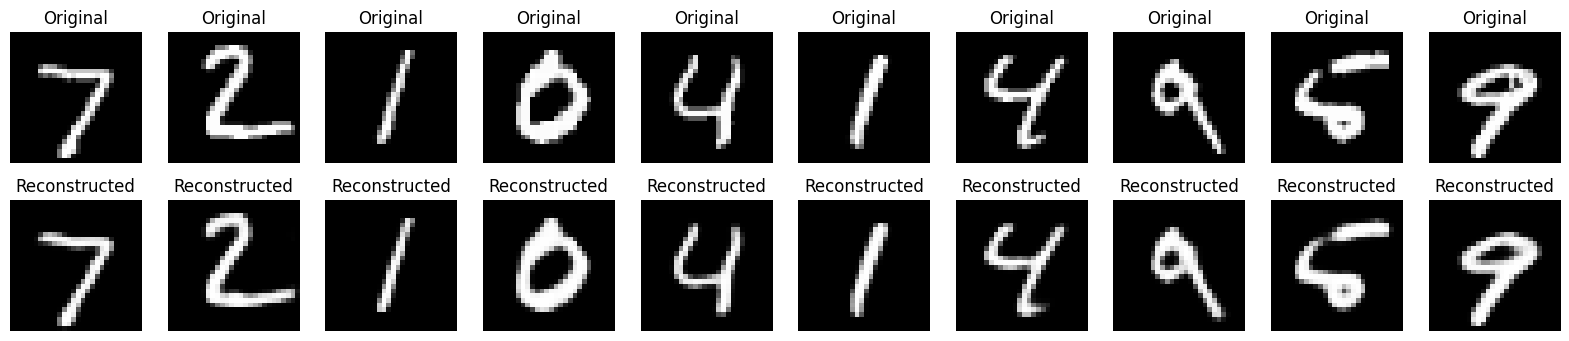

In [9]:
decoded_images = autoencoder.predict(x_test)

n = 10
plt.figure(figsize=(20,4))

for i in range(n):
    ax = plt.subplot(2, n, i+1)
    plt.imshow(x_test[i].reshape(28,28), cmap="gray")
    plt.title("Original")
    plt.gray()
    ax.axis('off')

    ax = plt.subplot(2, n, i+1+n)
    plt.imshow(decoded_images[i].reshape(28,28), cmap="gray")
    plt.title("Reconstructed")
    plt.gray()
    ax.axis('off')

plt.show()

In [10]:
autoencoder.save('autoencoder_mnist.keras')